## Multiple Linear Regression
### Pima Indians Diabetes Dataset
- **Course:** Statistics and Machine Learning
- **Format:** Individual task
- **Overview:** You will train, evaluate, and visualize ONE model. Afterwards you will present your results to your (3-4) groupmates and compare them.

---

### Fairness note
All 4-5 exercises in this group project use:
- the **same dataset**
- the **same cleaning steps**
- the **same train/test split** (fixed `random_state=42`, `test_size=0.2`)
- the **same number of required evaluation metrics** (4)
- the **same number of required visualizations** (3)

> This is intentional! It means when you compare results with your groupmates later, any differences you see come from the **algorithm itself**, not from different data handling. 
> Important Note: Do not change the split or the cleaning steps described below, even if you think another approach would work better as consistency across the group matters more here than optimizing your individual score.

---


## 1. Dataset

**File:** `diabetes.csv` in [Pima Indians Diabetes Dataset](https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv)

**Columns:**

| Column | Meaning |
|---|---|
| Pregnancies | Number of pregnancies |
| Glucose | Plasma glucose concentration |
| BloodPressure | Diastolic blood pressure (mm Hg) |
| SkinThickness | Triceps skinfold thickness (mm) |
| Insulin | 2-Hour serum insulin |
| BMI | Body mass index |
| DiabetesPedigreeFunction | Diabetes likelihood based on family history |
| Age | Age in years |
| Outcome | 0 = no diabetes, 1 = diabetes |

Place `diabetes.csv` in the same folder as this notebook before you start.


In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style='whitegrid')

## 2. Data Preparation (required -> identical for all 4-5 exercises)

Follow these steps **in order**. Do not skip or reorder any step.

1. **Load the dataset** with pandas and display `.shape`, `.head()`, `.info()`, and `.describe()`.
2. **Fix hidden missing values.** In this dataset, the columns `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI` use `0` to represent a missing value (a person cannot have 0 glucose or 0 BMI). Replace `0` with `NaN` in exactly these 5 columns only. Do **not** touch `Pregnancies`, `Age`, `DiabetesPedigreeFunction`, or `Outcome` -> a value of 0 is valid for these.
3. **Impute missing values** using the **median** of each column (fit the median on the training set only, after the split in Step 4, then apply it to both train and test -> this avoids data leakage).
4. **Define X and y.** Your target `y` is **BMI** (continuous). Your features `X` are all remaining columns **except** `BMI` and **except** `Outcome`.
5. **Drop `Outcome`** from the feature set entirely -> this exercise is a regression task, so the diabetes label is not used at all, neither as feature nor target.
6. **Report** how many missing values were found per column before imputation (one short printed table or Series is enough).

> **Note:** This is the only exercise in the group that does *not* use `Outcome`. Your groupmates are predicting `Outcome` (classification); you are predicting `BMI` (regression). This contrast is intentional and will come up in the debrief.


In [3]:
df = pd.read_csv('diabetes.csv')

print("Shape:", df.shape)
df.head()

Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [5]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [6]:
zero_as_missing = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
# print('\nZero counts in clinically implausible columns:')
# print((df[zero_as_missing] == 0).sum())
df[zero_as_missing] = df[zero_as_missing].replace(0, np.nan)
print('\nExplicit missing values (NaN):')
print(df.isnull().sum())



Explicit missing values (NaN):
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [7]:
X = df.drop(columns=["BMI", "Outcome"])
y = df["BMI"]

print("The Feature Columns:", list(X.columns))
print("Target: BMI")

The Feature Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'DiabetesPedigreeFunction', 'Age']
Target: BMI


## 3. Train/Test Split (required -> identical for all 4-5 exercises)

- Use `train_test_split` from `sklearn.model_selection`.
- `test_size=0.2`
- `random_state=42`
- For classification tasks: use `stratify=y` so the class balance is preserved in both sets.
- Print the shape of `X_train`, `X_test`, `y_train`, `y_test` to confirm the split.

**Do not change these settings.** They must be identical across all 4-5 group members so that your final comparison is fair.


In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.2)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (614, 7)
X_test: (154, 7)
y_train: (614,)
y_test: (154,)


In [9]:
# print("Remaining missing values in X_train", X_train.isna().sum())
# print("Remaining missing values in X_test", X_test.isna().sum())
# print("Remaining missing values in y_train", y_train.isna().sum())
# print("Remaining missing values in y_test", y_test.isna().sum())
X_train_medians = X_train.median()
X_train = X_train.fillna(X_train_medians)
X_test = X_test.fillna(X_train_medians)

y_train_medians = y_train.median()
y_train = y_train.fillna(y_train_medians)
y_test = y_test.fillna(y_train_medians)

print("Remaining missing values in X_train", X_train.isna().sum().sum())
print("Remaining missing values in X_test", X_test.isna().sum().sum())
print("Remaining missing values in y_train", y_train.isna().sum().sum())
print("Remaining missing values in y_test", y_test.isna().sum().sum())

Remaining missing values in X_train 0
Remaining missing values in X_test 0
Remaining missing values in y_train 0
Remaining missing values in y_test 0


## 4. Libraries

```
pandas
numpy
matplotlib
seaborn
sklearn.model_selection (train_test_split)
sklearn.preprocessing (StandardScaler)
sklearn.linear_model (LinearRegression, Ridge)
sklearn.metrics (mean_absolute_error, mean_squared_error, r2_score)
```

> **Scaling:** Apply `StandardScaler` to the features. Fit the scaler on `X_train` only, then transform both `X_train` and `X_test`.


In [10]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 5. Training & Hyperparameters

Train **two** models so you have something to compare:

1. **Model A -> Plain Multiple Linear Regression**
   `LinearRegression()` with default settings, trained on the scaled training data.

2. **Model B -> Ridge Regression (regularized)**
   `Ridge(alpha=...)`. Try **at least 3 values** of `alpha` (e.g., 0.1, 1.0, 10.0) and report the test-set R² for each. Keep the best-performing `alpha` as your final Model B.

Report the learned coefficients (β values) for Model A in a small table (feature name → coefficient), sorted by absolute value, largest first.


In [11]:
# Model A : Plain Multiple Linear Regression
model_a = LinearRegression()
model_a.fit(X_train_scaled, y_train)

coef_table = pd.DataFrame({
    "Feature" : X.columns,
    "Coefficient" : model_a.coef_
})

coef_table["abs"] = coef_table["Coefficient"].abs()
coef_table = coef_table.sort_values("abs", ascending=False).drop(columns='abs').reset_index(drop=True)

print(f"Intercept: {model_a.intercept_:.4f}")
coef_table

Intercept: 32.3482


,Feature,Coefficient
0,SkinThickness,3.579222
1,BloodPressure,1.318026
2,Age,-1.000106
3,Glucose,0.889115
4,DiabetesPedigreeFunction,0.531033
5,Insulin,0.346676
6,Pregnancies,-0.020931


In [12]:
# Model B
ridge_results = {}

ridge1 = Ridge(alpha=0.1)
ridge1.fit(X_train_scaled, y_train)
r2_1 = r2_score(y_test, ridge1.predict(X_test_scaled))
ridge_results[0.1]= r2_1

ridge2 = Ridge(alpha=1.0)
ridge2.fit(X_train_scaled, y_train)
r2_2 = r2_score(y_test, ridge2.predict(X_test_scaled))
ridge_results[1.0] = r2_2

ridge3 = Ridge(alpha=10.0)
ridge3.fit(X_train_scaled, y_train)
r2_3 = r2_score(y_test, ridge3.predict(X_test_scaled))
ridge_results[10.0] = r2_3

ridge4 = Ridge(alpha=100.0)
ridge4.fit(X_train_scaled, y_train)
r2_4 = r2_score(y_test, ridge4.predict(X_test_scaled))
ridge_results[100.0] = r2_4

print(ridge_results)

best_alpha = max(ridge_results, key=ridge_results.get)
print(f"\nThe Best Alpha: {best_alpha}")

model_b = Ridge(alpha=best_alpha)
model_b.fit(X_train_scaled, y_train)

{0.1: 0.2056883913852774, 1.0: 0.20625048482503594, 10.0: 0.21165261870377872, 100.0: 0.24881126927126762}

The Best Alpha: 100.0


Ridge(alpha=100.0)

## 6. Evaluation & Visualization

**Required metrics** (compute for both Model A and Model B, on the **test set**):
- MAE (Mean Absolute Error)
- MSE (Mean Squared Error)
- RMSE (Root Mean Squared Error)
- R² (Coefficient of Determination)

Present these in a small comparison table (rows = Model A / Model B, columns = the 4 metrics).

**Required visualizations** (3 total, for your best-performing model):
1. **Actual vs. Predicted scatter plot** -> y_test on x-axis, predictions on y-axis, plus a diagonal reference line (perfect prediction).
2. **Residual plot** -> predicted values (x-axis) vs. residuals = actual − predicted (y-axis), with a horizontal line at 0.
3. **Residual distribution histogram** -> a histogram (or KDE plot) of the residuals, to check whether errors are roughly centered around 0.


In [13]:
def evaluate(model, X_te, y_te):
    pred = model.predict(X_te)
    mae = mean_absolute_error(y_te, pred)
    mse = mean_squared_error(y_te, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_te, pred)
    return mae, mse, rmse, r2

results = pd.DataFrame(
    [evaluate(model_a, X_test_scaled, y_test),
     evaluate(model_b, X_test_scaled, y_test)],
     columns=["MAE", "MSE", "RMSE", "R^2"],
     index=["Model A (Linear Regression)", f"Model B (Ridge, alpha = {best_alpha})"]
).round(4)

results

,MAE,MSE,RMSE,R^2
Model A (Linear Regression),4.3763,34.7528,5.8951,0.2056
"Model B (Ridge, alpha = 100.0)",4.2535,32.8635,5.7327,0.2488


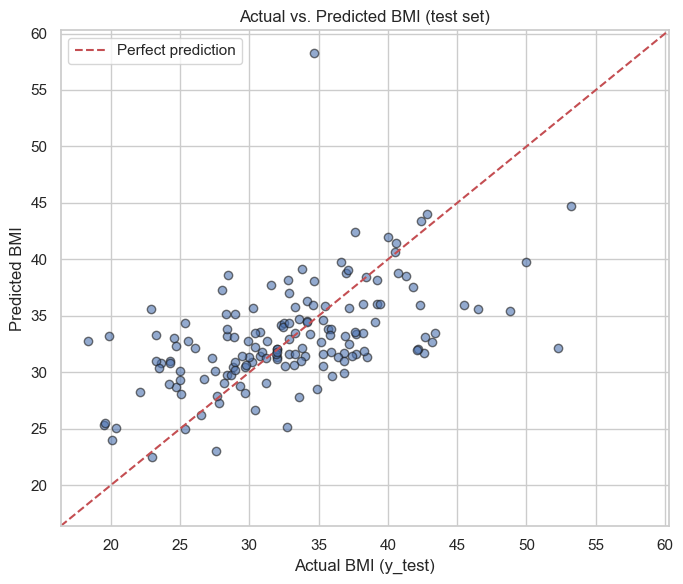

In [14]:
best_model = model_b if ridge_results[best_alpha] > r2_score(y_test, model_a.predict(X_test_scaled)) else model_a
y_pred = best_model.predict(X_test_scaled)
residuals = y_test - y_pred
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.6, edgecolor="k")
lims = [min(y_test.min(), y_pred.min()) - 2, max(y_test.max(), y_pred.max()) + 2]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlim(lims); plt.ylim(lims)
plt.xlabel("Actual BMI (y_test)")
plt.ylabel("Predicted BMI")
plt.title("Actual vs. Predicted BMI (test set)")
plt.legend()
plt.tight_layout()
plt.show()

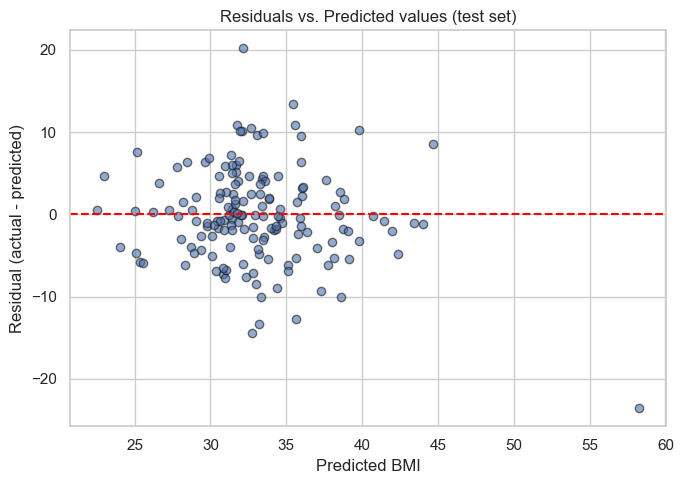

In [15]:
plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals, alpha=0.6, edgecolor="k")
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted BMI")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residuals vs. Predicted values (test set)")
plt.tight_layout()
plt.show()

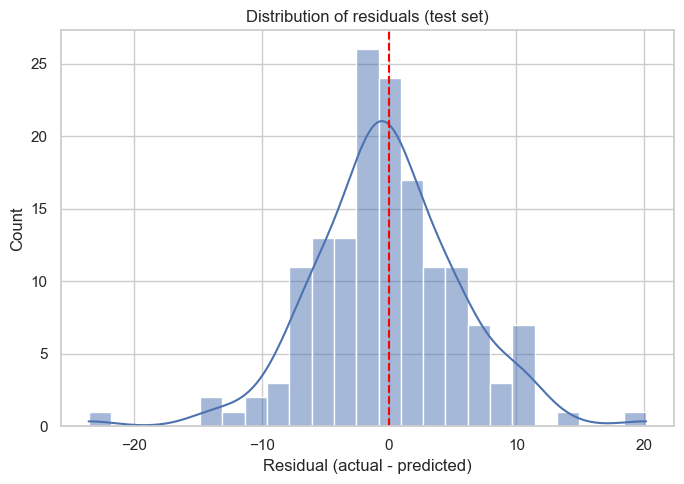

In [16]:
plt.figure(figsize=(7, 5))
sns.histplot(residuals, bins=25, kde=True)
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Residual (actual - predicted)")
plt.title("Distribution of residuals (test set)")
plt.tight_layout()
plt.show()

## 7. Reflection Questions (write short answers, 1–3 sentences each)

1. Which features seemed most important for Multiple Linear Regression, and how do you know (from your visualizations or model output)?
2. What was the effect of the hyperparameter(s) you tuned in Section 5? Did performance improve, get worse, or barely change?
3. Look at your error/residual or confusion matrix visualization -> where does the model struggle most? Any patterns?
4. If you had to explain this model to someone who has never studied ML, what is the one-sentence idea behind it?
BMI?
5. Did Ridge regression (Model B) outperform plain Linear Regression (Model A)? Why might regularization help or not help here?


Answer 1. The feature Skin Thickness (with coefficient value of around 3.5) seems the most important followed by Blood Pressure (with coefficient value of around 1.31). 
Answer 2. By increasing the alpha value we can saw that the R^2 steadily increased from 0.205 for alpha=0.1, to 0.206 for alpha = 1.0, to the finally 0.248 for alpha = 100. The performance did improve slightly for every different parameter.
Answer 3. We can see that the model struggles the most where there are high bmi values where we see large positive residuals for bmi levels above 40 while the predictions cluster in a narrow range of around 27-38.
Answer 4. This models tries to estimate a persons BMI by taking the weighted sum of their health measurements like skin thickness, blood pressure, age, etc.
Answer 5. Yes but just slightly as the R^2 score of ridge with alpha = 100 is 0.248 and for simple multiple linear regression it is around 0.205. But also the MAE, MSE, RMSE scores of simple multiple linear regression is better than ridge regression.
We used regularization for some features as they are correlated like insulin and glucose. We also did imputation for SkinThickness which helped in shrinking the coefficients. This helps in model's sensitivity to that noise.

## 8. Deliverables Checklist

Before the group debrief, make sure your notebook contains:

- [ ] Data loaded and cleaned (Section 2)
- [ ] Correct train/test split (Section 3)
- [ ] Model(s) trained with the required libraries (Section 4)
- [ ] Hyperparameter comparison completed (Section 5)
- [ ] All 4 required metrics reported (Section 6):
    - MAE
    - MSE
    - RMSE
    - R²
- [ ] All 3 required visualizations (Section 6):
    - Actual vs. Predicted scatter
    - Residual plot
    - Residual distribution histogram
- [ ] Reflection questions answered (Section 7)
---

## 9. Group Debrief (do this together, after everyone has finished)

Bring your metrics table and your 3 visualizations to the group. As a group, discuss:

- Whose model scored highest on Accuracy? On Recall? (If Applicable)
- If this model were used in a real clinic to screen for diabetes, would you prioritize Precision or Recall? Why? (If Applicable)
- Which visualizations were most convincing for explaining *why* a model performed the way it did?
- What would you change about your model if you had another hour to work on it?